# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [1]:
# !pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')


In [2]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [3]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [5]:
!pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn] [scikit-learn]


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [7]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. PC2 loads on number of children and age.


## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


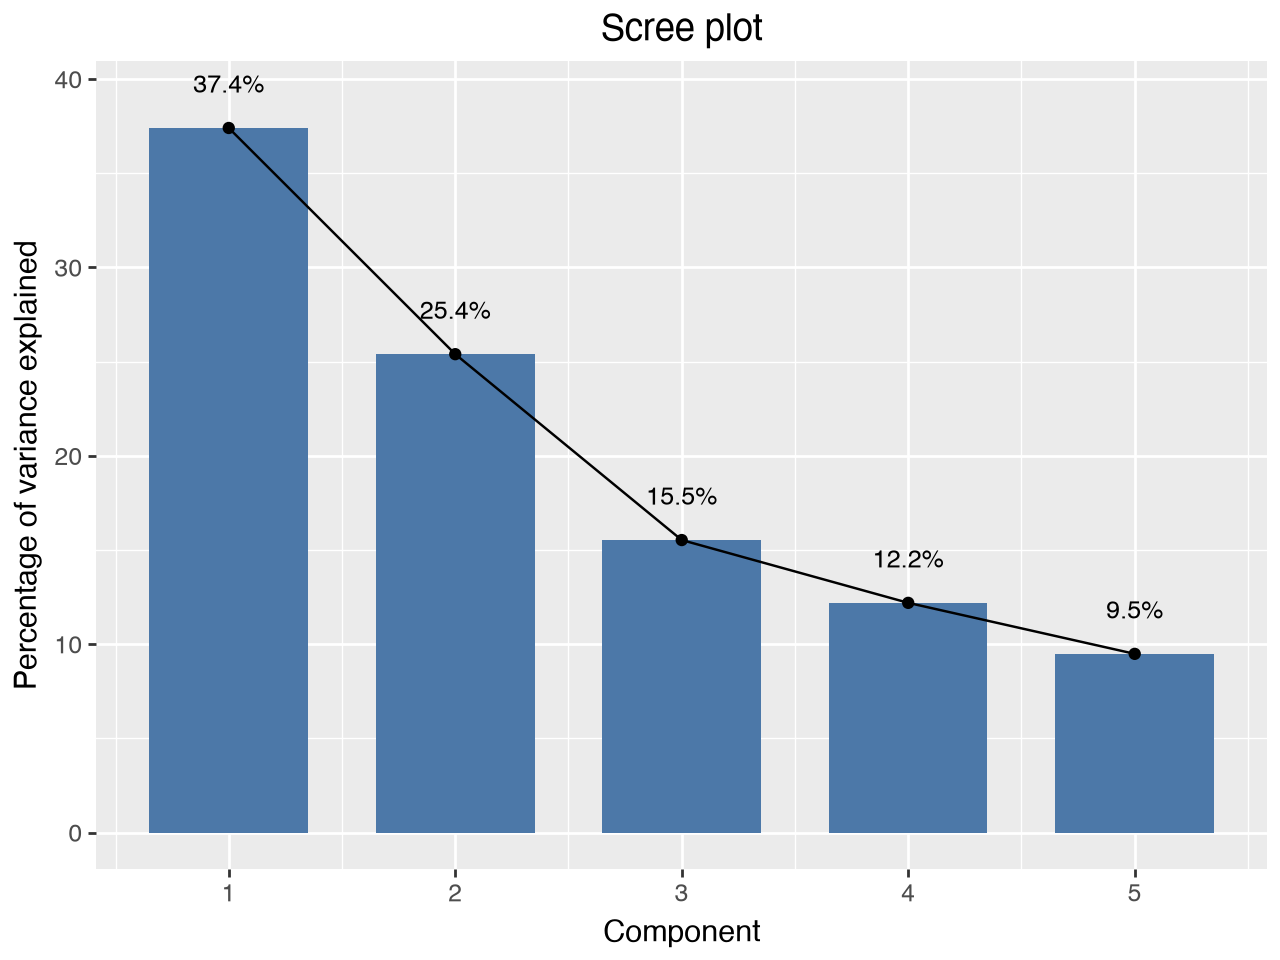

In [8]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


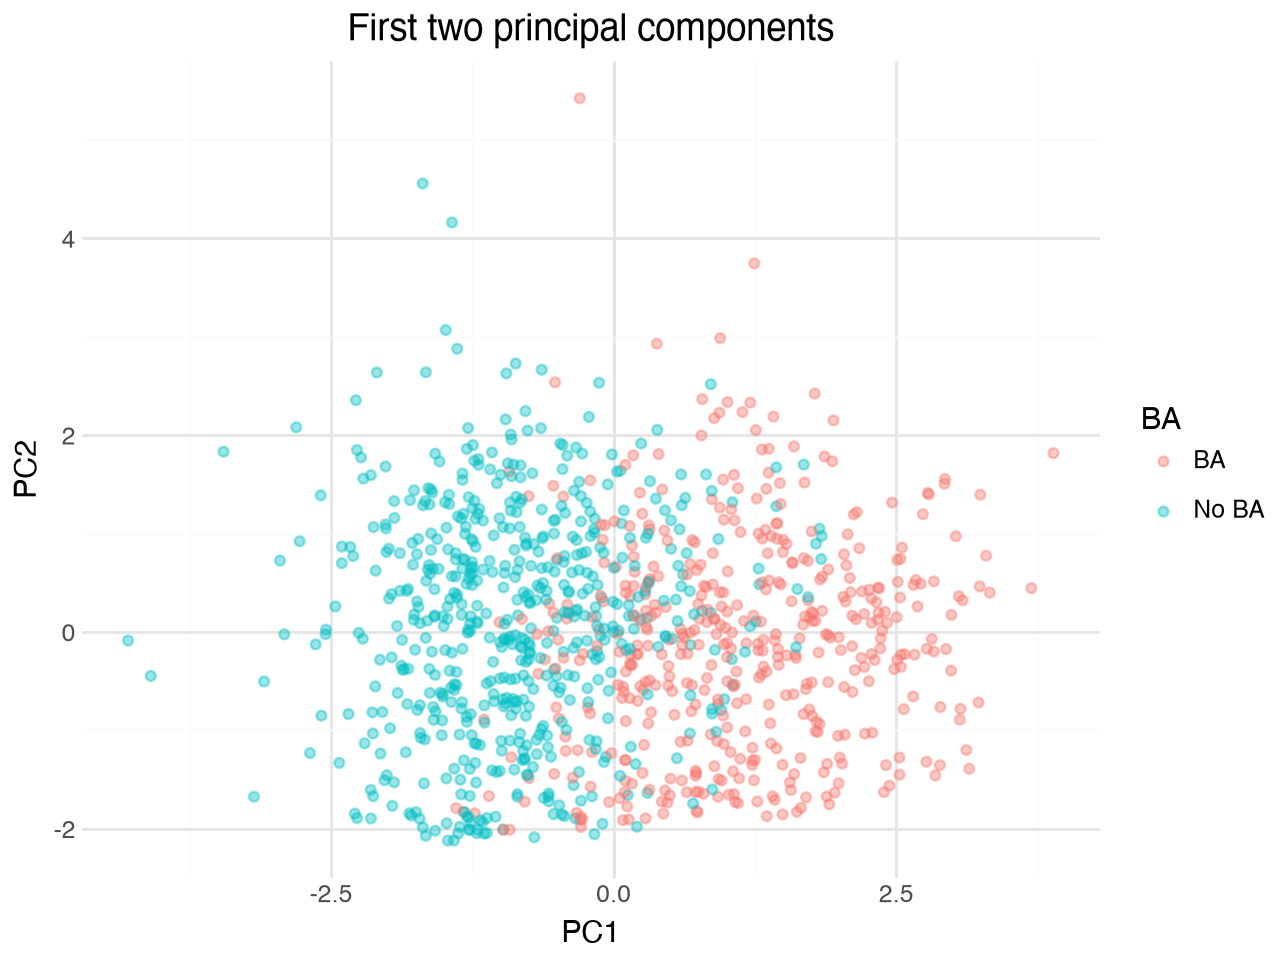

In [9]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


# Your answer here
1. Each variable to mean 0 and SD 1, fitting into a PCA


In [11]:
pca_cols = [
    "income_cont", "prestg10", "educ", "age",
    "binary_lvmus", "binary_artxbt", "binary_movie", "binary_creat"
]

work2 = df.dropna(subset=pca_cols + ["happy_bin"]).copy()

X2 = StandardScaler().fit_transform(work2[pca_cols])
pca2 = PCA().fit(X2)

In [12]:
work2[pca_cols + ["happy_bin"]].isna().sum()

income_cont      0
prestg10         0
educ             0
age              0
binary_lvmus     0
binary_artxbt    0
binary_movie     0
binary_creat     0
happy_bin        0
dtype: int64

In [13]:
# Above step is to ensure that variables are all 0

In [16]:
prop2 = pca2.explained_variance_ratio_

print(pd.DataFrame({
    "Standard deviation": pca2.explained_variance_ ** 0.5,
    "Proportion of variance": prop2,
    "Cumulative proportion": prop2.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
Standard deviation      1.607  1.299  1.005  0.848  0.793  0.722  0.710  0.590
Proportion of variance  0.323  0.211  0.126  0.090  0.079  0.065  0.063  0.044
Cumulative proportion   0.323  0.534  0.660  0.750  0.828  0.893  0.956  1.000


4. Loadings

In [18]:
loadings2 = pd.DataFrame(
    pca2.components_.T,
    index=pca_cols,
    columns=[f"PC{i}" for i in range(1, len(prop2) + 1)],
)
print(loadings2.round(3))

                 PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
income_cont    0.191  0.514 -0.184 -0.339  0.725 -0.150 -0.051 -0.027
prestg10       0.234  0.545  0.061  0.184 -0.389 -0.397  0.548  0.029
educ           0.278  0.512 -0.034  0.221 -0.278  0.496 -0.535 -0.019
age           -0.006  0.099  0.975 -0.129  0.109 -0.006 -0.084 -0.066
binary_lvmus   0.505 -0.197  0.050 -0.263 -0.061  0.058  0.020  0.791
binary_artxbt  0.467 -0.193  0.040  0.136  0.223  0.544  0.513 -0.339
binary_movie   0.448 -0.193 -0.064 -0.516 -0.331 -0.279 -0.230 -0.501
binary_creat   0.396 -0.232  0.052  0.657  0.266 -0.443 -0.295 -0.035


In [20]:
# based on the loadings: PC1 explains 32.3% of the variance and primarily captures cultural participation 
# all 4 cultural participation indicators load positively and relatively strongly (live music at 0.505, art exhibition attendance at 0.467, movies at 0.448 and creative activities at 0.396)
# socioeconomic variables load weakly on this component in pc1

PC2 explains 21.1% of the variance and captures a contrast between socioeconomic status and cultural participation. Income (0.514), occupational prestige (0.545), and education (0.512) load strongly and positively, while the four cultural-participation indicators load moderately negatively (about -0.19 to -0.23). Thus, higher PC2 scores represent respondents with higher socioeconomic status but lower cultural participation; lower scores represent respondents with lower socioeconomic status but more cultural participation.

Scatter PC1 against PC2

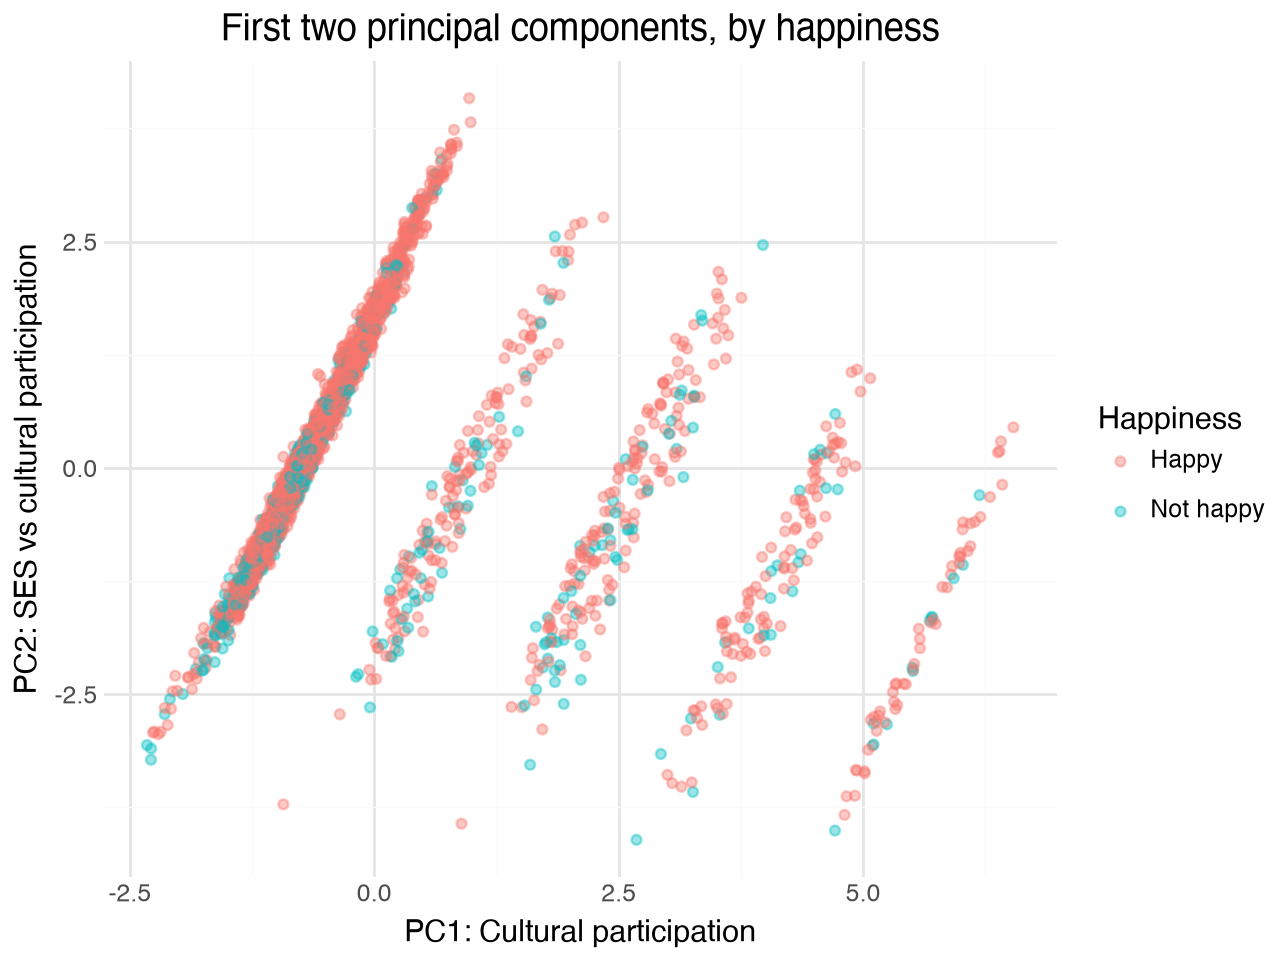

In [21]:
# 5. Create PCA scores and scatter PC1 against PC2
scores2 = pca2.transform(X2)

plot_df2 = work2.copy()
plot_df2["PC1"] = scores2[:, 0]
plot_df2["PC2"] = scores2[:, 1]
plot_df2["Happiness"] = np.where(
    plot_df2["happy_bin"] == 1, "Happy", "Not happy"
)

(
    ggplot(plot_df2, aes("PC1", "PC2", color="Happiness"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(
        x="PC1: Cultural participation",
        y="PC2: SES vs cultural participation",
        title="First two principal components, by happiness"
    )
)

Logit with three components 

In [22]:
# 6. Logit: happy_bin on PC1, PC2, and PC3
import statsmodels.api as sm

n_components = 3

scores2 = pca2.transform(X2)

component_df = pd.DataFrame(
    scores2[:, :n_components],
    columns=["PC1", "PC2", "PC3"],
    index=work2.index,
)

X_logit = sm.add_constant(component_df)
y_logit = work2["happy_bin"]

logit_model = sm.Logit(y_logit, X_logit).fit()
print(logit_model.summary())

# Odds ratios
print(pd.DataFrame({
    "Coefficient": logit_model.params,
    "Odds ratio": np.exp(logit_model.params),
}).round(3))

Optimization terminated successfully.
         Current function value: 0.522364
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 2842
Model:                          Logit   Df Residuals:                     2838
Method:                           MLE   Df Model:                            3
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                 0.03086
Time:                        18:44:05   Log-Likelihood:                -1484.6
converged:                       True   LL-Null:                       -1531.8
Covariance Type:            nonrobust   LLR p-value:                 2.323e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.2653      0.047     27.036      0.000       1.174       1.357
PC1            0.1053      0.

From the logit regression results, a one unit increase in PC1 is associated with an increase in the log odds of being happy by 0.1053 (p<0.01), ceteris paribus

A one unit increase in PC2 is associated with an increase in the log odds of being happy by 0.321, (p<0.01), ceteris paribus

A one unit increase in PC3 is associated with an decrease in the log odds of being happy by 0.0923 (p<0.01), ceteris paribus